In [1]:
import os
import xarray as xr
import socket
import subprocess
import numpy as np
import matplotlib.pyplot as plt
import cupy as cp
import cucim
from cucim.skimage.morphology import ball as GPUball
from scipy import ndimage
import cupyx.scipy.ndimage as GPUndimage
import cucim.skimage.morphology as cumorph
import skimage
from joblib import Parallel, delayed

#paths
host = socket.gethostname()
if host == 'mpc2959.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    toppathSSD = '/mnt/SSD/fische_r/COELY'
    temppath = '/mnt/SSD/fische_r/tmp'
    temppath_2 = '/mpc/homes/fische_r/NAS/tmp'
    training_path = '/mpc/homes/fische_r/NAS/DASCOELY/processing/05_water_GDL_ML/'
    
elif host == 'mpc2053.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    toppathSSD = os.path.join(toppath, 'processing')
    temppath = '/mnt/SSD_2TB_nvme0n1/Robert/tmp/'
    temppath_2 = '/mpc/homes/fische_r/NAS/tmp'
    training_path = '/mpc/homes/fische_r/NAS/DASCOELY/processing/05_water_GDL_ML/'
else:
    print('host '+host+' currently not supported')

# fetch githash
cwd = os.getcwd()
os.chdir(gitpath)
git_sha = subprocess.check_output(['git', 'rev-parse', '--short', 'HEAD']).decode().strip()
githash = subprocess.check_output(['git', 'rev-parse', 'HEAD']).decode().strip()
os.chdir(cwd)

In [2]:
sample = '1'
segpath = os.path.join(training_path, sample, sample+'water_segmentation.nc')

In [3]:
seg_data = xr.open_dataset(segpath)

In [4]:
seg_data

<xarray.Dataset>
Dimensions:    (x: 750, y: 340, z: 1916, timestep: 31, feature: 106)
Coordinates:
  * x          (x) int64 0 1 2 3 4 5 6 7 8 ... 742 743 744 745 746 747 748 749
  * y          (y) int64 0 1 2 3 4 5 6 7 8 ... 332 333 334 335 336 337 338 339
  * z          (z) int64 0 1 2 3 4 5 6 7 ... 1909 1910 1911 1912 1913 1914 1915
  * timestep   (timestep) int64 0 1 2 3 4 5 6 7 8 ... 22 23 24 25 26 27 28 29 30
  * feature    (feature) object 'Gaussian_4D_Blur_0.0' ... 'full_temp_min_Gau...
Data variables:
    segmented  (x, y, z, timestep) uint8 ...
    t_utc      (timestep) float64 ...
    time       (timestep) float64 ...
Attributes: (12/21)
    name:                                              1
    voxel size:                                        2.75 um
    voxel:                                             2.75e-06
    post rotation cropping coordinates [a:b,c:d,e:f]:  [ 120 1062  320  972  ...
    rotation angle 1:                                  -22
    rotation angle 2:                                  -22
    ...                                                ...
    git_sha_registration:                              612e92b
    githash_registration:                              612e92b28895745f6b422c...
    05_ML_cropping:                                    [120 870  10 350  50 -50]
    pytrain_git:                                       e42ad75
    05_coely_gitsha:                                   53e8ce2
    GDL_crop:                                          0

In [8]:
test = seg_data['segmented'].sel(timestep = 0)

In [174]:
# water  = test == 2

In [9]:
fiber = test == 0

In [10]:
im = fiber.sel(y =250)

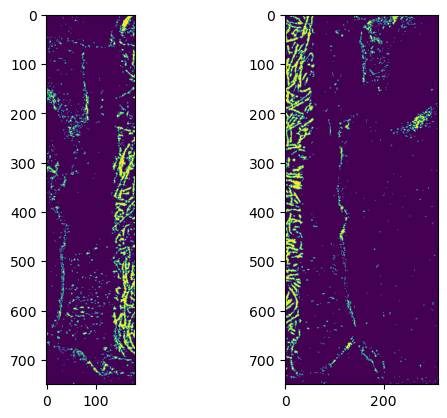

In [11]:
a = 180
b = -310

fig, axs = plt.subplots(1,2)
axs[0].imshow(im[:,:a])
axs[1].imshow(im[:,b:])

crops = {
'1': (180,-310)
}

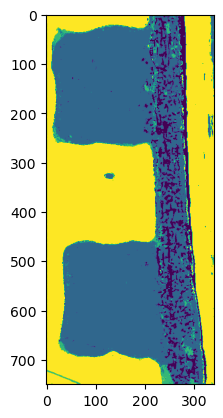

In [12]:
plt.imshow(test[:,:,650])

In [13]:
def get_GDL_mask(segim):
    fiber = segim == 0
    fibercp = cp.array(fiber)
    fibercp = GPUndimage.binary_opening(fibercp, structure=GPUball(1))
    dst = ndimage.distance_transform_cdt(~cp.asnumpy(fibercp))
    fibercp = cp.array(dst<3)
    labels = cucim.skimage.measure.label(fibercp)
    fibercp = labels == cp.argmax(cp.bincount(labels[fibercp]))
    del labels
    fibercp = GPUndimage.binary_erosion(fibercp, structure=GPUball(3))
    fibercp = GPUndimage.binary_dilation(fibercp, structure=GPUball(6))
    fibercp = GPUndimage.binary_fill_holes(fibercp)
    fibercp = GPUndimage.binary_erosion(fibercp, structure=GPUball(3))
    mask = cp.asnumpy(fibercp)
    del fibercp
    mempool = cp.get_default_memory_pool()
    mempool.free_all_blocks()
    return mask

In [18]:
def get_channel_masks(segim, mask, a, b):
    back = segim == 3
    FFcp = cp.array(back)
    FFcp = GPUndimage.binary_opening(FFcp, GPUball(4))
    
    FFcp = FFcp + cp.array(mask)
    FFcp[:5,:] = True
    FFcp[-5:,:] = True
    FFcp[:,:5] = True
    FFcp[:,-5:] = True
    FFcp = GPUndimage.binary_closing(FFcp, GPUball(4))
    FFcp[:5,:] = True
    FFcp[-5:,:] = True
    FFcp[:,:5] = True
    FFcp[:,-5:] = True
    FFlabels = cucim.skimage.measure.label(~FFcp[:,:,a:b], connectivity=2)
    FFcp[...] = False
    id, count = cp.unique(FFlabels, return_counts = True)
    id1,id2 = id[cp.argsort(count)][-3:-1]
    FFcp[:,:,a:b] = FFlabels==int(id1)

    channel1 = cp.asnumpy(FFcp)
    FFcp[...] = False
    FFcp[:,:,a:b] = FFlabels==int(id2)
    channel2 = cp.asnumpy(FFcp)

    del FFcp, FFlabels
    mempool = cp.get_default_memory_pool()
    mempool.free_all_blocks()

    # check which channel is on top and assign accordingly
    if np.argmax(channel1[:,:,650].sum(axis=1))>np.argmax(channel2[:,:,650].sum(axis=1)):
        return channel1, channel2
    else:
        return channel2, channel1
    

In [15]:
def get_channel_GDL_masks(channel1, channel2,a,b):
    GDLchannel1 = channel1.sum(axis=1)>100
    GDLchannel2 = channel2.sum(axis=1)>100
    GDLland = ~np.bitwise_or(GDLchannel1, GDLchannel2)
    GDLland[:,:a] = False
    GDLland[:,b:] = False
    labels = skimage.measure.label(GDLland)
    GDLrib = labels == np.argmax(np.bincount(labels[GDLland]))
    
    return GDLchannel1, GDLchannel2, GDLland, GDLrib

In [28]:
def get_timestep_mask(ts, seg_data, a,b):
    test = seg_data['segmented'].sel(timestep = ts)

    gpu_id = ts%5
    while cp.cuda.Device(gpu_id).mem_info[0]<8E9:
        time.sleep(1)
    
    with cp.cuda.Device(gpu_id):
        mask = get_GDL_mask(test)
        channel1, channel2 = get_channel_masks(test, mask, a, b)
        GDLchannel1, GDLchannel2, GDLland, GDLrib = get_channel_GDL_masks(channel1, channel2,a,b)

    segments = np.zeros(mask.shape, dtype = np.uint8)
    segments[channel1] = 1
    segments[channel2] = 2
    segments = segments + GDLchannel1[:,None,:]*3*mask
    segments = segments + GDLchannel2[:,None,:]*4*mask
    segments = segments + GDLrib[:,None,:]*5*mask
    segments = segments + GDLland[:,None,:]*6*mask

    return segments
    
    

In [29]:
# mask = get_GDL_mask(test)

In [30]:
a, b = crops[sample]
# channel1, channel2 = get_channel_masks(test, mask, a, b)

In [31]:
ts = 0
segments = get_timestep_mask(ts, seg_data, a,b)

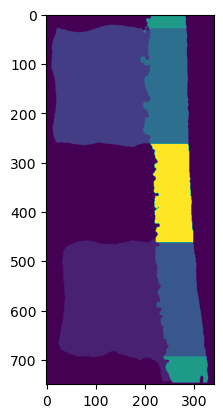

In [32]:
plt.imshow(segments[:,:,650])

In [184]:
# GDLchannel1, GDLchannel2, GDLland, GDLrib = get_channel_GDL_masks(channel1, channel2,a,b)

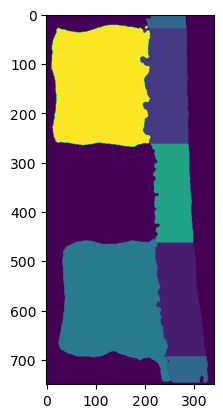

In [185]:
plt.imshow(1*(mask*GDLchannel1[:,None,:])[:,:,650]+2*(mask*GDLchannel2[:,None,:])[:,:,650]+3*(mask*GDLrib[:,None,:])[:,:,650]+4*(mask*GDLland[:,None,:])[:,:,650]+5*channel1[:,:,650]*1+6*channel2[:,:,650]*2)

In [186]:
test1 = 1*(mask*GDLchannel1[:,None,:])[:,:,650]+2*(mask*GDLchannel2[:,None,:])[:,:,650]+3*(mask*GDLrib[:,None,:])[:,:,650]+4*(mask*GDLland[:,None,:])[:,:,650]+5*channel1[:,:,650]*1+6*channel2[:,:,650]*2

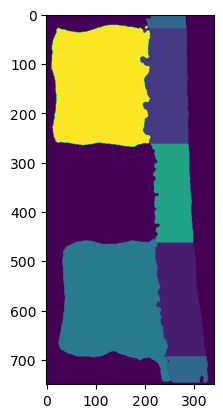

In [188]:
plt.imshow(test1)

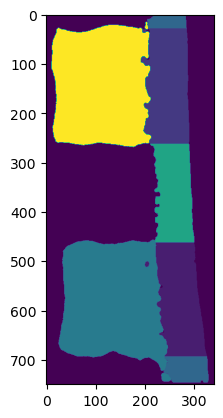

In [189]:
plt.imshow(test2)

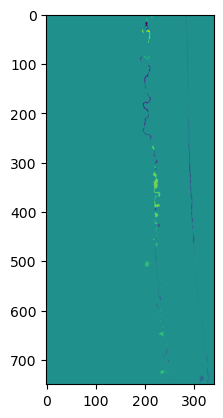

In [190]:
plt.imshow(test1-test2)